In [139]:
API_KEY = "1eae25a540a2077718f17a6c8f322c70"

In [140]:
print("API key loaded:", bool(API_KEY))
print("Key length:", len(API_KEY))

API key loaded: True
Key length: 32


In [141]:
import requests
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns

In [142]:
API_KEY = "1eae25a540a2077718f17a6c8f322c70"

CITY = "Pune"
COUNTRY = "IN"

In [143]:
url = "https://api.openweathermap.org/data/2.5/weather"

params = {
    "q": f"{CITY},{COUNTRY}",
    "appid": API_KEY,
    "units": "metric"
}

response = requests.get(url, params=params)

print(response.status_code)

200


In [144]:
weather_data = response.json()

weather_data

{'coord': {'lon': 73.8553, 'lat': 18.5196},
 'weather': [{'id': 804,
   'main': 'Clouds',
   'description': 'overcast clouds',
   'icon': '04n'}],
 'base': 'stations',
 'main': {'temp': 27.91,
  'feels_like': 26.83,
  'temp_min': 27.91,
  'temp_max': 27.91,
  'pressure': 1016,
  'humidity': 25,
  'sea_level': 1016,
  'grnd_level': 943},
 'visibility': 10000,
 'wind': {'speed': 3.21, 'deg': 272, 'gust': 4.83},
 'clouds': {'all': 85},
 'dt': 1791386127,
 'sys': {'country': 'IN', 'sunrise': 1791334567, 'sunset': 1791377320},
 'timezone': 19800,
 'id': 1259229,
 'name': 'Pune',
 'cod': 200}

In [145]:
temperature = weather_data["main"]["temp"]

print("Temperature:", temperature, "°C")

Temperature: 27.91 °C


In [146]:
humidity = weather_data["main"]["humidity"]

print("Humidity:", humidity, "%")

Humidity: 25 %


In [147]:
wind_speed = weather_data["wind"]["speed"]

print("Wind Speed:", wind_speed, "m/s")

Wind Speed: 3.21 m/s


In [148]:
rain = weather_data.get("rain", {})

precipitation = rain.get("1h", 0)

print("Precipitation:", precipitation, "mm")

Precipitation: 0 mm


In [149]:
weather_df = pd.DataFrame([{
    "City": CITY,
    "Temperature": temperature,
    "Humidity": humidity,
    "Wind_Speed": wind_speed,
    "Precipitation": precipitation
}])

weather_df

,City,Temperature,Humidity,Wind_Speed,Precipitation
0,Pune,27.91,25,3.21,0


In [150]:
print(weather_df.isnull().sum())

City             0
Temperature      0
Humidity         0
Wind_Speed       0
Precipitation    0
dtype: int64


In [151]:
weather_df = weather_df.fillna(0)

weather_df

,City,Temperature,Humidity,Wind_Speed,Precipitation
0,Pune,27.91,25,3.21,0


In [152]:
average_temperature = weather_df["Temperature"].mean()

print("Average Temperature:", average_temperature, "°C")

Average Temperature: 27.91 °C


In [153]:
maximum_temperature = weather_df["Temperature"].max()
minimum_temperature = weather_df["Temperature"].min()

print("Maximum Temperature:", maximum_temperature, "°C")
print("Minimum Temperature:", minimum_temperature, "°C")

Maximum Temperature: 27.91 °C
Minimum Temperature: 27.91 °C


In [154]:
import time

weather_records = []

for i in range(5):

    response = requests.get(url, params=params)
    data = response.json()

    record = {
        "City": CITY,
        "Temperature": data["main"]["temp"],
        "Humidity": data["main"]["humidity"],
        "Wind_Speed": data["wind"]["speed"],
        "Precipitation": data.get("rain", {}).get("1h", 0)
    }

    weather_records.append(record)

    time.sleep(2)

weather_df = pd.DataFrame(weather_records)

weather_df

,City,Temperature,Humidity,Wind_Speed,Precipitation
0,Pune,27.91,25,3.21,0
1,Pune,27.91,25,3.21,0
2,Pune,27.91,25,3.21,0
3,Pune,27.91,25,3.21,0
4,Pune,27.91,25,3.21,0


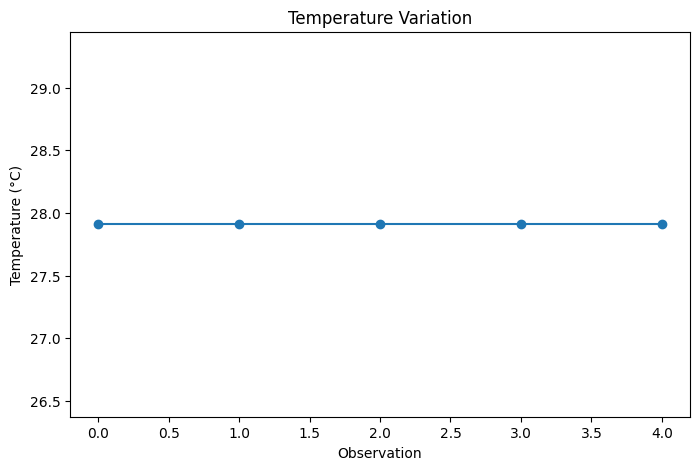

In [155]:
plt.figure(figsize=(8, 5))

plt.plot(
    weather_df.index,
    weather_df["Temperature"],
    marker="o"
)

plt.title("Temperature Variation")
plt.xlabel("Observation")
plt.ylabel("Temperature (°C)")

plt.show()

In [156]:
data["main"]["humidity"]

25

In [157]:
print(data["main"])

{'temp': 27.91, 'feels_like': 26.83, 'temp_min': 27.91, 'temp_max': 27.91, 'pressure': 1016, 'humidity': 25, 'sea_level': 1016, 'grnd_level': 943}


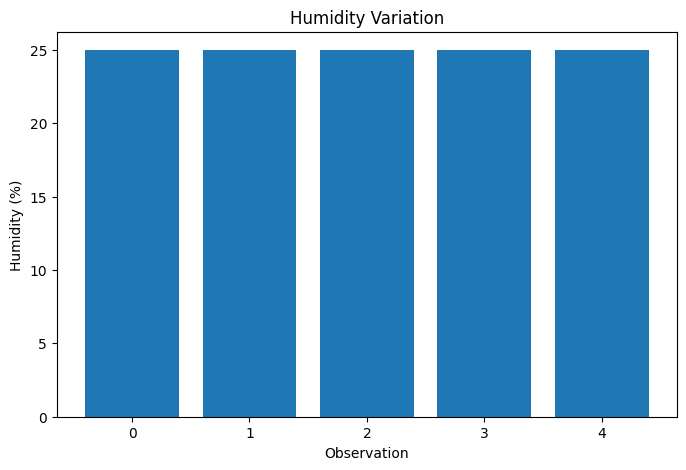

In [158]:
plt.figure(figsize=(8, 5))

plt.bar(
    weather_df.index,
    weather_df["Humidity"]
)

plt.title("Humidity Variation")
plt.xlabel("Observation")
plt.ylabel("Humidity (%)")

plt.show()

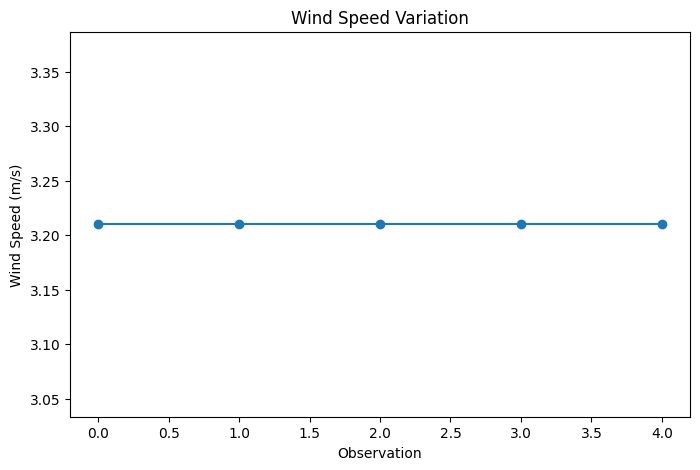

In [159]:
plt.figure(figsize=(8, 5))

plt.plot(
    weather_df.index,
    weather_df["Wind_Speed"],
    marker="o"
)

plt.title("Wind Speed Variation")
plt.xlabel("Observation")
plt.ylabel("Wind Speed (m/s)")

plt.show()

In [160]:
weather_summary = weather_df[[
    "Temperature",
    "Humidity",
    "Wind_Speed",
    "Precipitation"
]].agg(["mean", "min", "max"])

weather_summary

,Temperature,Humidity,Wind_Speed,Precipitation
mean,27.91,25.0,3.21,0.0
min,27.91,25.0,3.21,0.0
max,27.91,25.0,3.21,0.0


In [161]:
latitude = weather_data["coord"]["lat"]
longitude = weather_data["coord"]["lon"]

print("Latitude:", latitude)
print("Longitude:", longitude)

Latitude: 18.5196
Longitude: 73.8553


In [162]:
correlation = weather_df[
    ["Temperature", "Humidity", "Wind_Speed", "Precipitation"]
].corr()

correlation

,Temperature,Humidity,Wind_Speed,Precipitation
Temperature,NaN,NaN,NaN,NaN
Humidity,NaN,NaN,NaN,NaN
Wind_Speed,NaN,NaN,NaN,NaN
Precipitation,NaN,NaN,NaN,NaN


c:\Users\asjun\AppData\Local\Programs\Python\Python313\Lib\site-packages\seaborn\matrix.py:202: RuntimeWarning: All-NaN slice encountered
  vmin = np.nanmin(calc_data)
c:\Users\asjun\AppData\Local\Programs\Python\Python313\Lib\site-packages\seaborn\matrix.py:207: RuntimeWarning: All-NaN slice encountered
  vmax = np.nanmax(calc_data)


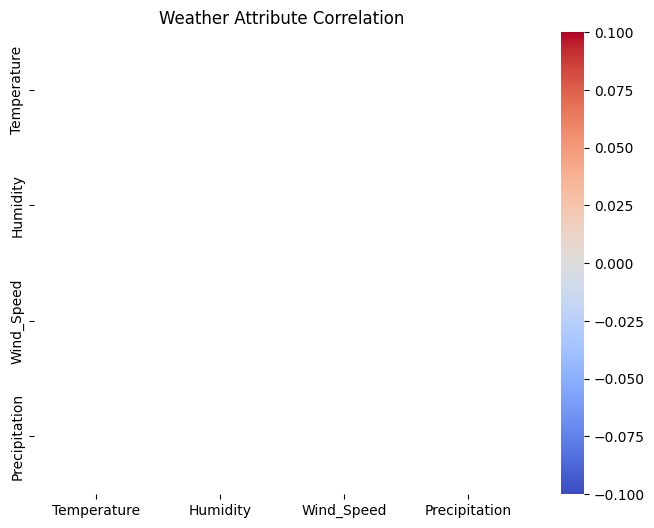

In [163]:
plt.figure(figsize=(8, 6))

sns.heatmap(
    correlation,
    annot=True,
    cmap="coolwarm"
)

plt.title("Weather Attribute Correlation")

plt.show()